In [1]:
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
pd.set_option("display.max_columns", 20)

Python: 3.12.14
NumPy: 2.0.2
pandas: 2.3.3
scikit-learn: 1.6.1


# Task 1: Data Preprocessing
Gumar — student ID seed: **3242**

This is a synthetic dataset of Almaty apartments.

## Step 2 — Load and inspect

In [2]:
YOUR_ID = 3242
raw = pd.read_csv("data/almaty_apartments_raw.csv")
ids = raw["listing_id"].drop_duplicates().sample(frac=0.9, random_state=YOUR_ID)
df = raw[raw["listing_id"].isin(ids)].reset_index(drop=True)

print("Shape:", df.shape)
print(df.dtypes)
print("Missing values:")
print(df.isna().sum())
display(df.describe(include="all").T)

for col in ["listed_date", "rooms", "area_m2", "price_kzt"]:
    print(col, df[col].sample(10, random_state=YOUR_ID).tolist())

Shape: (1154, 11)
listing_id           object
listed_date          object
district             object
rooms                object
area_m2              object
floor                 int64
total_floors          int64
year_built          float64
building_type        object
ceiling_height_m    float64
price_kzt            object
dtype: object
Missing values:
listing_id            0
listed_date           0
district              0
rooms                 0
area_m2               0
floor                 0
total_floors          0
year_built           52
building_type         0
ceiling_height_m    142
price_kzt             0
dtype: int64
listed_date ['2026-03-25', '2026-07-16', '2026-08-05', '2026-07-05', '2026-08-24', '2026-07-25', '2026-08-16', '2026-08-24', '2026-02-11', '2026-05-01']
rooms ['3', '3', '4', '1', '1', '2', '2', '1', '1', '4']
area_m2 ['75.8', '87.8', '126.6', '40.8', '36.3', '47.7', '54.1', '36.3', '36.4', '93.9']
price_kzt ['32370000', '91720000', '49960000', '23060000', '2412000

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
listing_id,1154,1080,ALM-11147,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
listed_date,1154,245,2026-04-18,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,1154,47,Medeu,147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rooms,1154,6,2,431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_m2,1154,654,42.0,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
floor,1154.0,NaN,NaN,NaN,5.954939,4.763228,-1.0,2.0,5.0,8.0,30.0
total_floors,1154.0,NaN,NaN,NaN,10.565858,6.083511,3.0,5.0,9.0,12.0,25.0
year_built,1102.0,NaN,NaN,NaN,1950.824864,279.273563,0.0,1973.0,1987.0,2009.75,2024.0
building_type,1154,3,panel,474,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ceiling_height_m,1012.0,NaN,NaN,NaN,2.718379,0.449092,0.0,2.62,2.77,2.91,3.2


In [3]:
print("Exact duplicates:", df.duplicated().sum())
distinct = df.drop_duplicates()
print("Extra reposts:", distinct["listing_id"].duplicated().sum())
pair_ids = distinct.loc[distinct["listing_id"].duplicated(), "listing_id"].head(2)
display(distinct[distinct["listing_id"].isin(pair_ids)].sort_values(["listing_id", "listed_date"]))

Exact duplicates: 33
Extra reposts: 41


,listing_id,listed_date,district,rooms,area_m2,floor,total_floors,year_built,building_type,ceiling_height_m,price_kzt
53,ALM-11017,2026-04-30,turksib,1,30.3,1,12,1981.0,panel,NaN,13430000
209,ALM-11017,2026-06-25,turksib,1,30.3,1,12,1981.0,panel,NaN,12810000
160,ALM-11147,2026-05-26,Almaly,2,56.7,4,9,2018.0,monolith,2.86,59610000
149,ALM-11147,2026-06-25,Almaly,2,56.7,4,9,2018.0,monolith,2.86,57130000


### Data types and validation
- `listed_date`: text, needs date conversion.
- `rooms`: text because it contains `studio`.
- `area_m2`: text because of decimal commas and `m²`.
- `price_kzt`: text because of commas, spaces and `₸`.

One clean row should be the latest posting of one listing. The two repost examples have different dates and prices.

| Column | Type | Valid values |
|---|---|---|
| listing_id | string | ALM- followed by digits, unique after cleaning |
| listed_date | datetime | Valid date, no later than 2026-09-27 |
| district | string | The 8 district names from the task |
| rooms | integer | 1–20, studio = 1 |
| area_m2 | float | Above 0; inspect areas above 200 m² |
| floor | integer or NaN | From 1 to total_floors |
| total_floors | integer | 1–100 |
| year_built | integer or NaN | 1800–2026, not after the listing year |
| building_type | string | panel, brick, monolith |
| ceiling_height_m | float or NaN | 2–6 m |
| price_kzt | number | Above 0 KZT |

These ranges are checks for this dataset. An unusual value is not always an error.

## Step 3 — Clean and transform

In [4]:
cleaning_log = []

# Save the row counts and number of changed cells.
def log(step, operation, before, after, changed=0):
    cleaning_log.append({
        "Step": step, "Operation": operation,
        "Rows before": int(before), "Rows after": int(after),
        "Cells changed": int(changed)
    })

before = len(df)
df = df.drop_duplicates().copy()
log("3a", "Remove exact duplicates", before, len(df))

old = df["listed_date"].copy()
df["listed_date"] = pd.to_datetime(old, errors="coerce")
print("New missing dates:", (old.notna() & df["listed_date"].isna()).sum())
assert df["listed_date"].notna().all()
log("3a", "Parse dates", len(df), len(df), len(df))
print("Same-ID, same-date conflicts:", df.duplicated(["listing_id", "listed_date"]).sum())

before = len(df)
df = df.sort_values(["listed_date", "listing_id"])
df = df.drop_duplicates("listing_id", keep="last").reset_index(drop=True)
log("3a", "Keep latest repost", before, len(df))
print("Reposts removed:", before - len(df))

New missing dates: 0
Same-ID, same-date conflicts: 0
Reposts removed: 41


I removed exact copies. For reposts, I kept the latest date because it has the newer asking price.

In [5]:
print("Original district spellings:")
print(df["district"].value_counts().to_string())
canonical = ["Alatau", "Almaly", "Auezov", "Bostandyk", "Medeu", "Nauryzbay", "Turksib", "Zhetysu"]
prefix_map = {
    "alata": "Alatau", "almal": "Almaly", "auezo": "Auezov", "bosta": "Bostandyk",
    "medeu": "Medeu", "naury": "Nauryzbay", "turks": "Turksib", "zhety": "Zhetysu",
    "алата": "Alatau", "алмал": "Almaly", "ауэзо": "Auezov", "боста": "Bostandyk",
    "медеу": "Medeu", "науры": "Nauryzbay", "туркс": "Turksib", "жетыс": "Zhetysu"
}
old = df["district"].copy()
df["district"] = old.str.strip().str.casefold().str[:5].map(prefix_map)
print("Unmapped spellings:", old[df["district"].isna()].unique().tolist())
assert df["district"].isna().sum() == 0
assert set(df["district"].unique()) == set(canonical)
log("3b", "Normalize district spelling/case/whitespace", len(df), len(df), old.ne(df.district).sum())
print("Canonical district count:", df.district.nunique())
print("Missing districts:", df.district.isna().sum())

Original district spellings:
district
Medeu            139
Bostandyk        121
Turksib          118
Zhetysu          115
Auezov           113
Almaly           111
Alatau           103
Nauryzbay         94
medeu             10
turksib            9
auezov             8
bostandyk          7
Auezovskiy         7
Наурызбайский      7
 Auezov            7
AUEZOV             7
Alatauskiy         6
Nauryzbayskiy      6
Медеуский          5
 Turksib           5
Bostandykskiy      5
ALMALY             5
nauryzbay          5
Almalinskiy        5
BOSTANDYK          4
TURKSIB            4
 Bostandyk         4
ZHETYSU            4
 Zhetysu           4
MEDEU              4
Zhetysuskiy        3
 Alatau            3
Турксибский        3
 Almaly            3
Бостандыкский      3
almaly             3
ALATAU             3
Ауэзовский         2
Medeuskiy          2
zhetysu            2
 Nauryzbay         2
Turksibskiy        2
NAURYZBAY          2
 Medeu             2
alatau             1
Алатауский       

In [6]:
for col in ["rooms", "area_m2", "price_kzt"]:
    old = df[col].copy()
    if col == "rooms":
        text = old.replace({"studio": "1"})
    elif col == "area_m2":
        text = old.str.replace("m²", "", regex=False).str.strip()
        text = text.str.replace(",", ".", regex=False)
    else:
        text = old.str.replace(r"[₸,\s]", "", regex=True)

    df[col] = pd.to_numeric(text, errors="coerce")
    new_missing = (old.notna() & df[col].isna()).sum()
    print(col, "new NaNs:", new_missing)
    assert new_missing == 0
    log("3c", "Parse " + col, len(df), len(df), old.notna().sum())

print(df.dtypes)
display(pd.DataFrame(cleaning_log))

rooms new NaNs: 0
area_m2 new NaNs: 0
price_kzt new NaNs: 0
listing_id                  object
listed_date         datetime64[ns]
district                    object
rooms                        int64
area_m2                    float64
floor                        int64
total_floors                 int64
year_built                 float64
building_type               object
ceiling_height_m           float64
price_kzt                    int64
dtype: object


,Step,Operation,Rows before,Rows after,Cells changed
0,3a,Remove exact duplicates,1154,1121,0
1,3a,Parse dates,1121,1121,1121
2,3a,Keep latest repost,1121,1080,0
3,3b,Normalize district spelling/case/whitespace,1080,1080,166
4,3c,Parse rooms,1080,1080,1080
5,3c,Parse area_m2,1080,1080,1080
6,3c,Parse price_kzt,1080,1080,1080


Studio = 1 room. For area, a comma means a decimal point. For price, commas and spaces separate thousands. I checked that parsing created no new NaNs.

## Step 4 — Sentinels, impossible values and outliers

In [7]:
display(df.describe().T)
for col in ["floor", "year_built", "ceiling_height_m"]:
    print(col, "smallest values and frequencies:")
    print(df[col].value_counts(dropna=False).sort_index().head(6))
sentinels = {"floor": -1, "year_built": 0, "ceiling_height_m": 0}
for col, sentinel in sentinels.items():
    mask = df[col].eq(sentinel)
    count = int(mask.sum())
    df.loc[mask, col] = np.nan
    log("4", f"Replace {col} sentinel {sentinel} with NaN", len(df), len(df), count)
    print(col, "sentinels replaced:", count)

impossible_floor = df["floor"] > df["total_floors"]
print("Impossible floor > total_floors:", impossible_floor.sum())
display(df.loc[impossible_floor, ["listing_id", "floor", "total_floors"]])
count_impossible = int(impossible_floor.sum())
df.loc[impossible_floor, "floor"] = np.nan
log("4", "Set contradictory floor to NaN", len(df), len(df), count_impossible)

floor smallest values and frequencies:
floor
-1     10
 1    138
 2    126
 3    149
 4    104
 5    107
Name: count, dtype: int64
year_built smallest values and frequencies:
year_built
0.0       21
1950.0     3
1951.0     2
1952.0     5
1953.0     5
1954.0     3
Name: count, dtype: int64
ceiling_height_m smallest values and frequencies:
ceiling_height_m
0.00    22
2.50     6
2.51    21
2.52    19
2.53    27
2.54    10
Name: count, dtype: int64
floor sentinels replaced: 10
year_built sentinels replaced: 21
ceiling_height_m sentinels replaced: 22
Impossible floor > total_floors: 10


,count,mean,min,25%,50%,75%,max,std
listed_date,1080,2026-05-01 01:48:00,2026-01-01 00:00:00,2026-03-05 00:00:00,2026-04-29 00:00:00,2026-06-29 00:00:00,2026-08-31 00:00:00,NaN
rooms,1080.0,2.265741,1.0,2.0,2.0,3.0,5.0,1.008184
area_m2,1080.0,69.1825,25.3,45.275,58.6,79.425,879.0,60.325603
floor,1080.0,5.942593,-1.0,2.0,5.0,8.0,30.0,4.780292
total_floors,1080.0,10.57037,3.0,5.0,9.0,12.0,25.0,6.131449
year_built,1031.0,1949.838021,0.0,1973.0,1987.0,2009.0,2024.0,282.001026
ceiling_height_m,948.0,2.718059,0.0,2.62,2.77,2.91,3.2,0.453446
price_kzt,1080.0,46603138.888889,11440000.0,28402500.0,40275000.0,57682500.0,193000000.0,25285513.020889


,listing_id,floor,total_floors
8,ALM-10729,15.0,12
115,ALM-10851,13.0,12
140,ALM-10944,4.0,3
307,ALM-10044,30.0,25
574,ALM-10420,11.0,9
620,ALM-10636,6.0,5
699,ALM-10628,6.0,5
757,ALM-10321,10.0,5
834,ALM-10266,13.0,12
1008,ALM-10695,14.0,12


In [8]:
checks = {
    "bad listing_id": ~df.listing_id.str.fullmatch(r"ALM-\d+", na=False),
    "duplicate listing_id": df.listing_id.duplicated(),
    "bad listed_date": df.listed_date.isna() | df.listed_date.gt(pd.Timestamp("2026-09-27")),
    "bad district": ~df.district.isin(canonical),
    "bad rooms": ~df.rooms.between(1, 20) | df.rooms.mod(1).ne(0),
    "bad area": df.area_m2.isna() | df.area_m2.le(0),
    "bad floor": df.floor.notna() & (~df.floor.ge(1) | df.floor.gt(df.total_floors) | df.floor.mod(1).ne(0)),
    "bad total_floors": ~df.total_floors.between(1, 100) | df.total_floors.mod(1).ne(0),
    "bad year_built": df.year_built.notna() & (~df.year_built.between(1800, 2026) | df.year_built.gt(df.listed_date.dt.year) | df.year_built.mod(1).ne(0)),
    "bad building_type": ~df.building_type.isin(["panel", "brick", "monolith"]),
    "bad ceiling": df.ceiling_height_m.notna() & ~df.ceiling_height_m.between(2, 6),
    "bad price": df.price_kzt.isna() | df.price_kzt.le(0)
}
print("Remaining validation violations:")
print(pd.Series({name: int(mask.sum()) for name, mask in checks.items()}))
assert not any(mask.any() for mask in checks.values())

Remaining validation violations:
bad listing_id          0
duplicate listing_id    0
bad listed_date         0
bad district            0
bad rooms               0
bad area                0
bad floor               0
bad total_floors        0
bad year_built          0
bad building_type       0
bad ceiling             0
bad price               0
dtype: int64


The values -1 in floor and 0 in year or ceiling height mean unknown, so I replaced them with NaN. When floor > total_floors, I cannot know which value is wrong. I set floor to NaN and kept total_floors as a working assumption.

Global fences: -85460.48882338108 1527464.2898623454
Global outliers: 0
District outliers: 12


,listing_id,district,rooms,area_m2,price_per_m2
3,ALM-10910,Zhetysu,3,736.0,73437.500000
150,ALM-10276,Turksib,2,604.0,55678.807947
167,ALM-10405,Turksib,1,356.0,52893.258427
207,ALM-11122,Zhetysu,2,647.0,62859.350850
245,ALM-10072,Medeu,2,530.0,121264.150943
315,ALM-10058,Bostandyk,2,555.0,119405.405405
514,ALM-10921,Zhetysu,3,668.0,57724.550898
655,ALM-10264,Bostandyk,1,495.0,86222.222222
770,ALM-10909,Alatau,2,565.0,57716.814159
842,ALM-10605,Nauryzbay,2,54.3,680662.983425


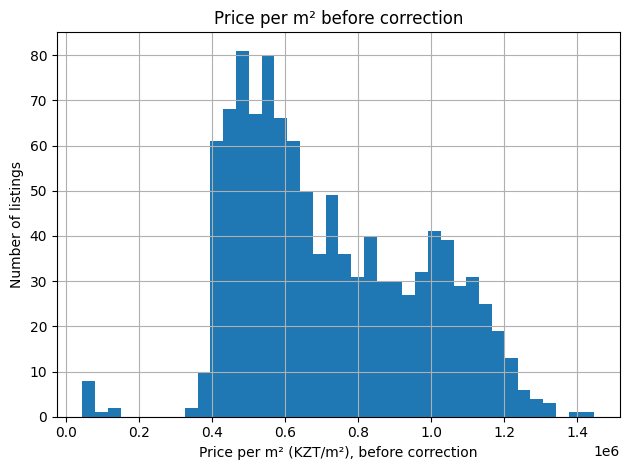

In [9]:
df["area_before_fix"] = df["area_m2"]
df["price_per_m2"] = df["price_kzt"] / df["area_m2"]

def fences(values, groups=None):
    grouped = values if groups is None else values.groupby(groups)
    q1 = grouped.quantile(0.25)
    q3 = grouped.quantile(0.75)
    if groups is not None:
        q1 = groups.map(q1)
        q3 = groups.map(q3)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

global_low, global_high = fences(df["price_per_m2"])
global_flag = (df["price_per_m2"] < global_low) | (df["price_per_m2"] > global_high)
print("Global fences:", global_low, global_high)
print("Global outliers:", global_flag.sum())

low, high = fences(df["price_per_m2"], df["district"])
group_flag = (df["price_per_m2"] < low) | (df["price_per_m2"] > high)
print("District outliers:", group_flag.sum())
display(df.loc[group_flag, ["listing_id", "district", "rooms", "area_m2", "price_per_m2"]])

df["price_per_m2"].hist(bins=40)
plt.xlabel("Price per m² (KZT/m²), before correction")
plt.ylabel("Number of listings")
plt.title("Price per m² before correction")
plt.tight_layout()
plt.show()

Districts have different price levels. Global IQR misses the very low values, so I also used IQR within each district. A flag means the row needs checking, not automatic deletion.

In [10]:
fix_area = (df["area_m2"] > 200) & (df["price_per_m2"] < low)
audit = df.loc[fix_area, ["listing_id", "district", "rooms", "area_m2", "price_per_m2"]].copy()

df.loc[fix_area, "area_m2"] = df.loc[fix_area, "area_m2"] / 10
df["price_per_m2"] = df["price_kzt"] / df["area_m2"]
log("4", "Divide incorrect areas by 10", len(df), len(df), fix_area.sum())
log("4", "Update price per m²", len(df), len(df), fix_area.sum())

audit["area_after"] = df.loc[fix_area, "area_m2"]
audit["area_per_room_after"] = audit["area_after"] / audit["rooms"]
audit["price_per_m2_after"] = df.loc[fix_area, "price_per_m2"]
audit["district_low"] = low[fix_area]
audit["district_high"] = high[fix_area]
display(audit)
print("Corrected areas:", fix_area.sum())
print("Corrected prices inside district fences:",
      audit["price_per_m2_after"].between(audit["district_low"], audit["district_high"]).all())

print("Kept flagged rows:")
display(df.loc[group_flag & ~fix_area, ["listing_id", "district", "rooms", "area_m2", "price_kzt", "price_per_m2"]])
log("4", "Keep plausible price outlier", len(df), len(df))

df.to_csv("data/almaty_apartments_clean.csv", index=False)
print("Clean CSV saved:", df.shape)
print(df.isna().sum())

Corrected areas: 11
Corrected prices inside district fences: True
Kept flagged rows:
Clean CSV saved: (1080, 13)
listing_id            0
listed_date           0
district              0
rooms                 0
area_m2               0
floor                20
total_floors          0
year_built           70
building_type         0
ceiling_height_m    154
price_kzt             0
area_before_fix       0
price_per_m2          0
dtype: int64


,listing_id,district,rooms,area_m2,price_per_m2,area_after,area_per_room_after,price_per_m2_after,district_low,district_high
3,ALM-10910,Zhetysu,3,736.0,73437.500000,73.6,24.533333,7.343750e+05,373001.965835,8.753655e+05
150,ALM-10276,Turksib,2,604.0,55678.807947,60.4,30.200000,5.567881e+05,288086.303940,7.666354e+05
167,ALM-10405,Turksib,1,356.0,52893.258427,35.6,35.600000,5.289326e+05,288086.303940,7.666354e+05
207,ALM-11122,Zhetysu,2,647.0,62859.350850,64.7,32.350000,6.285935e+05,373001.965835,8.753655e+05
245,ALM-10072,Medeu,2,530.0,121264.150943,53.0,26.500000,1.212642e+06,640626.723921,1.470480e+06
315,ALM-10058,Bostandyk,2,555.0,119405.405405,55.5,27.750000,1.194054e+06,541630.860252,1.372954e+06
514,ALM-10921,Zhetysu,3,668.0,57724.550898,66.8,22.266667,5.772455e+05,373001.965835,8.753655e+05
655,ALM-10264,Bostandyk,1,495.0,86222.222222,49.5,49.500000,8.622222e+05,541630.860252,1.372954e+06
770,ALM-10909,Alatau,2,565.0,57716.814159,56.5,28.250000,5.771681e+05,292875.689310,6.630688e+05
950,ALM-10440,Auezov,3,879.0,55028.441411,87.9,29.300000,5.502844e+05,423597.982678,8.964121e+05


,listing_id,district,rooms,area_m2,price_kzt,price_per_m2
842,ALM-10605,Nauryzbay,2,54.3,36960000,680662.983425


I corrected the 11 very large areas by dividing them by 10. Their room counts are small, and their prices per m² are very low. After correction, area per room is reasonable and price per m² is inside the district fences; this suggests a decimal error.

I kept the other flagged row because its area and price are possible. I did not drop any outlier rows.

The clean CSV still has NaNs. `area_before_fix` is for Step 6 only; `price_per_m2` is not a model feature because it uses the target. This full-data price check follows the lab instructions, so the later R² is only a lab sanity check.

## Step 5 — Missing data: split, diagnose, compare and fill

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

NUMERIC = ["rooms", "area_m2", "floor", "total_floors", "year_built", "ceiling_height_m"]
train, test = train_test_split(df, test_size=0.2, random_state=YOUR_ID)
train, test = train.copy(), test.copy()
print("Train/test rows:", len(train), len(test))
display(pd.DataFrame({"train": train[NUMERIC].isna().sum(),
                      "test": test[NUMERIC].isna().sum()}))

top_missing = train[NUMERIC].isna().sum().sort_values(ascending=False).head(2).index
for col in top_missing:
    rate = train.assign(missing=train[col].isna()).groupby("building_type")["missing"].mean()
    print("Missing rate:", col)
    print(rate)

print("Training rows lost with dropna():", len(train) - len(train.dropna()))

Train/test rows: 864 216
Missing rate: ceiling_height_m
building_type
brick       0.156951
monolith    0.041237
panel       0.231429
Name: missing, dtype: float64
Missing rate: year_built
building_type
brick       0.071749
monolith    0.058419
panel       0.062857
Name: missing, dtype: float64
Training rows lost with dropna(): 189


,train,test
rooms,0,0
area_m2,0,0
floor,16,4
total_floors,0,0
year_built,55,15
ceiling_height_m,128,26


Ceiling height looks MAR: its missing rate differs by building type (about 4%–23%). Year built looks closer to MCAR across these groups (about 6%–7%). This comparison cannot prove MCAR or rule out MNAR.

In [12]:
known = train[train["ceiling_height_m"].notna()]
hidden = known.sample(frac=0.15, random_state=YOUR_ID).index
rest = train.drop(index=hidden)
answers = train.loc[hidden, "ceiling_height_m"]
global_median = rest["ceiling_height_m"].median()
group_medians = rest.groupby("building_type")["ceiling_height_m"].median()
pred_global = pd.Series(global_median, index=hidden)
pred_group = train.loc[hidden, "building_type"].map(group_medians).fillna(global_median)
mae_global = mean_absolute_error(answers, pred_global)
mae_group = mean_absolute_error(answers, pred_group)
print("Values hidden:", len(hidden))
print(f"Global median MAE: {mae_global:.5f} m")
print(f"Building-type median MAE: {mae_group:.5f} m")
ceiling_strategy = "group" if mae_group < mae_global else "global"
print("Winning ceiling strategy:", ceiling_strategy)

Values hidden: 110
Global median MAE: 0.14627 m
Building-type median MAE: 0.06923 m
Winning ceiling strategy: group


I chose building-type medians for ceiling height because their masking MAE was lower. I also used building-type medians for year built because building types have different construction periods. For floor, I used the training median, capped at total_floors.

In [13]:
ceiling_medians = train.groupby("building_type")["ceiling_height_m"].median()
year_medians = train.groupby("building_type")["year_built"].median().round()
ceiling_global = train["ceiling_height_m"].median()
year_global = round(train["year_built"].median())
floor_median = round(train["floor"].median())

print("Ceiling medians:")
print(ceiling_medians)
print("Year medians:")
print(year_medians)
print("Floor median:", floor_median)

for name, frame in [("train", train), ("test", test)]:
    counts = frame[NUMERIC].isna().sum()

    frame["ceiling_height_m"] = frame["ceiling_height_m"].fillna(
        frame["building_type"].map(ceiling_medians)).fillna(ceiling_global)
    frame["year_built"] = frame["year_built"].fillna(
        frame["building_type"].map(year_medians)).fillna(year_global)

    missing_floor = frame["floor"].isna()
    frame.loc[missing_floor, "floor"] = np.minimum(
        floor_median, frame.loc[missing_floor, "total_floors"])

    for col in ["ceiling_height_m", "year_built", "floor"]:
        log("5d", name + ": fill " + col, len(frame), len(frame), counts[col])

    print(name, "remaining NaNs:", frame[NUMERIC].isna().sum().sum())

Ceiling medians:
building_type
brick       2.93
monolith    2.86
panel       2.60
Name: ceiling_height_m, dtype: float64
Year medians:
building_type
brick       1980.0
monolith    2014.0
panel       1977.0
Name: year_built, dtype: float64
Floor median: 4
train remaining NaNs: 0
test remaining NaNs: 0


## Step 6 — Scaling, encoding and model sanity check

In [14]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression

for scaler in [StandardScaler(), MinMaxScaler(), RobustScaler()]:
    scaled = scaler.fit_transform(train[["area_before_fix"]]).ravel()
    q1, q3 = np.percentile(scaled, [25, 75])
    print(type(scaler).__name__)
    print("IQR:", round(q3 - q1, 3),
          "min:", round(scaled.min(), 3), "max:", round(scaled.max(), 3))

StandardScaler
IQR: 0.539 min: -0.706 max: 12.83
MinMaxScaler
IQR: 0.04 min: 0.0 max: 1.0
RobustScaler
IQR: 1.0 min: -0.978 max: 24.131


Bad areas increase the standard deviation, so StandardScaler compresses the normal values. MinMaxScaler compresses them near 0 because the maximum is very large. I would choose RobustScaler if the outliers remained: its central IQR stays 1, but it does not fix wrong data.

In [15]:
correct_scaler = StandardScaler().fit(train[["area_m2"]])
leaky_scaler = StandardScaler().fit(pd.concat([train, test])[["area_m2"]])
correct_mean = correct_scaler.transform(test[["area_m2"]]).mean()
leaky_mean = leaky_scaler.transform(test[["area_m2"]]).mean()
print(f"Scaled test mean, train-only fit: {correct_mean:.6f}")
print(f"Scaled test mean, combined fit:   {leaky_mean:.6f}")

Scaled test mean, train-only fit: 0.010554
Scaled test mean, combined fit:   0.008459


Fitting on train + test uses information from the test set. This is leakage even when the difference is small. The final model uses a train-only fit.

In [16]:
CATEGORICAL = ["district", "building_type"]
pre = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)
])
X_train = pre.fit_transform(train[NUMERIC + CATEGORICAL])
X_test = pre.transform(test[NUMERIC + CATEGORICAL])
model = LinearRegression().fit(X_train, train["price_kzt"])
score = model.score(X_test, test["price_kzt"])
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("NaN counts:", np.isnan(X_train).sum(), np.isnan(X_test).sum())
print(f"Test R²: {score:.6f}")
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

X_train shape: (864, 17)
X_test shape: (216, 17)
NaN counts: 0 0
Test R²: 0.910490


## Step 7 — EDA on cleaned, unfilled data

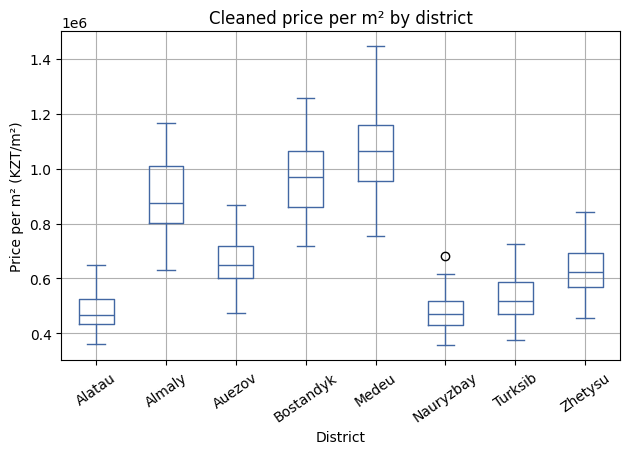

Observation: Medeu has the highest district median (1,064,354 KZT/m²), while Alatau has the lowest (467,442 KZT/m²).


In [17]:
df.boxplot(column="price_per_m2", by="district", rot=35, color="#4267a3")
plt.xlabel("District")
plt.ylabel("Price per m² (KZT/m²)")
plt.title("Cleaned price per m² by district")
plt.suptitle("")
plt.tight_layout(); plt.show()
medians = df.groupby("district")["price_per_m2"].median()
print(f"Observation: {medians.idxmax()} has the highest district median ({medians.max():,.0f} KZT/m²), while {medians.idxmin()} has the lowest ({medians.min():,.0f} KZT/m²).")

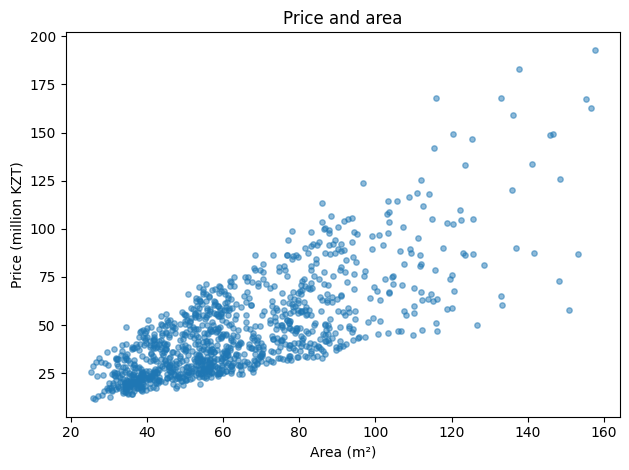

Observation: area and price have a positive correlation of 0.749


In [18]:
plt.scatter(df["area_m2"], df["price_kzt"] / 1000000, alpha=0.5, s=15)
plt.xlabel("Area (m²)")
plt.ylabel("Price (million KZT)")
plt.title("Price and area")
plt.tight_layout()
plt.show()

correlation = df["area_m2"].corr(df["price_kzt"])
print("Observation: area and price have a positive correlation of", round(correlation, 3))

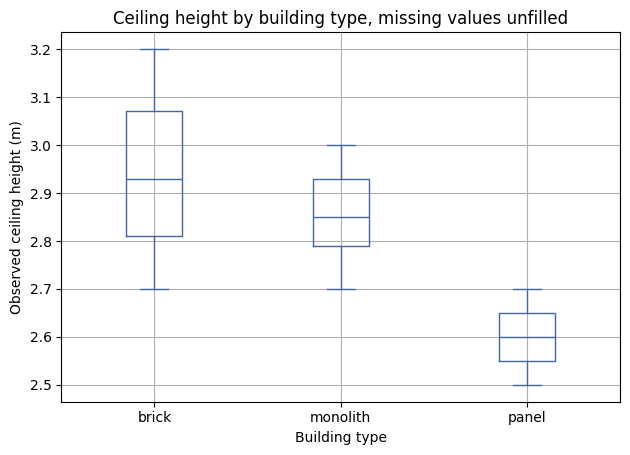

Observation: median observed ceiling height is 2.60 m in panel, 2.93 m in brick, and 2.85 m in monolith buildings.


In [19]:
df.boxplot(column="ceiling_height_m", by="building_type", color="#4267a3")
plt.xlabel("Building type")
plt.ylabel("Observed ceiling height (m)")
plt.title("Ceiling height by building type, missing values unfilled")
plt.suptitle("")
plt.tight_layout(); plt.show()
heights = df.groupby("building_type")["ceiling_height_m"].median()
print(f"Observation: median observed ceiling height is {heights['panel']:.2f} m in panel, {heights['brick']:.2f} m in brick, and {heights['monolith']:.2f} m in monolith buildings.")

### Cleaning log
Row removals are shown by the before/after counts. Cells changed counts edited or converted cells. Step 5 uses train/test copies and does not fill the saved CSV.

In [20]:
display(pd.DataFrame(cleaning_log))
saved = pd.read_csv("data/almaty_apartments_clean.csv")
print("Clean CSV saved, shape:", saved.shape)
print("Missing numeric cells in CSV:", saved[NUMERIC].isna().sum().sum())
print("NaNs in X_train and X_test:", np.isnan(X_train).sum(), np.isnan(X_test).sum())

Clean CSV saved, shape: (1080, 13)
Missing numeric cells in CSV: 244
NaNs in X_train and X_test: 0 0


,Step,Operation,Rows before,Rows after,Cells changed
0,3a,Remove exact duplicates,1154,1121,0
1,3a,Parse dates,1121,1121,1121
2,3a,Keep latest repost,1121,1080,0
3,3b,Normalize district spelling/case/whitespace,1080,1080,166
4,3c,Parse rooms,1080,1080,1080
5,3c,Parse area_m2,1080,1080,1080
6,3c,Parse price_kzt,1080,1080,1080
7,4,Replace floor sentinel -1 with NaN,1080,1080,10
8,4,Replace year_built sentinel 0 with NaN,1080,1080,21
9,4,Replace ceiling_height_m sentinel 0 with NaN,1080,1080,22


### Git history

In [21]:
!git log --oneline

579d338 (HEAD -> main) Save verified notebook outputs and cleaned dataset
4b7bc7c Add train-only imputation, scaling and EDA workflow
e037969 Add inspection, validation and documented cleaning rules
3313424 Initialize project and pinned data dependencies
